# Unit 11 — Melakukan Proses Review Pemodelan
**Kode unit:** J.62DMI00.015.1 · **Acuan:** SKKNI No. 299 Tahun 2020 (Ilmuwan Data) · **Proyek:** Prediksi Arah Harian IHSG

> Notebook ini me-*review* seluruh proses secara kritis: ketercapaian kriteria bisnis dan teknis, keputusan penting di tiap tahap, analisis *drift* data, keterbatasan, rekomendasi perbaikan, rencana penerapan dan monitoring, serta matriks keterlacakan artefak. Semua angka dibaca dari artefak tahap sebelumnya — tidak ada yang diketik ulang secara manual.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

RAW = Path('../data/raw/market_data.csv')
PROC = Path('../data/processed')
FIG = Path('../figures')
REP = Path('../reports')
MOD = Path('../models')
for p in (PROC, FIG, REP, MOD):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EDA_END = '2022-12-31'
C_UP, C_DOWN, C_NAVY, C_ACCENT, C_GREY = '#1a9850', '#d73027', '#1f3a5f', '#e08214', '#8c8c8c'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10, 'axes.titleweight': 'bold',
})

def to_json(obj, path):
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(obj, f, ensure_ascii=False, indent=2,
                  default=lambda o: o.item() if hasattr(o, 'item') else str(o))

In [2]:
def load(path):
    with open(path, encoding='utf-8') as f:
        return json.load(f)

biz = load(REP / 'business_objective.json')
tech = load(REP / 'technical_objective.json')
split_info = load(REP / 'split_info.json')
meta = load(MOD / 'model_metadata.json')
ev = load(REP / 'evaluation_metrics.json')
validation = pd.read_csv(REP / 'validation_report.csv')
anomalies = pd.read_csv(REP / 'anomalies.csv')
cleaning = pd.read_csv(REP / 'cleaning_log.csv')
cvres = pd.read_csv(REP / 'cv_results.csv')
train = pd.read_csv(PROC / 'train.csv', parse_dates=['Date'])
test = pd.read_csv(PROC / 'test.csv', parse_dates=['Date'])
m = ev['metrics']
print('Proyek :', biz['proyek'])
print('Model  :', meta['model_name'], '| parameter:', meta['tuned_params'])
print(f'Uji    : accuracy {m["accuracy"]:.3f} | F1-macro {m["f1_macro"]:.3f} | ROC-AUC {m["roc_auc"]:.3f}')

Proyek : Prediksi Arah Harian IHSG Berbasis Indikator Pasar Global dan Domestik
Model  : Random Forest | parameter: {'max_depth': 8, 'min_samples_leaf': 20}
Uji    : accuracy 0.560 | F1-macro 0.558 | ROC-AUC 0.569


## 1. Review proses per tahap: keputusan penting dan buktinya

In [3]:
best_cv = cvres.set_index('id').loc[meta['model_id']]
n_usd = int((anomalies.variabel == 'USDIDR').sum()); n_hol = int((anomalies.variabel == 'IHSG').sum())
process = pd.DataFrame([
    ('1–2 Pemahaman bisnis & tujuan teknis', 'Masalah dirumuskan sebagai dukungan keputusan, bukan sistem trading; KPI ditetapkan sebelum pemodelan',
     f'{len(biz["tujuan_bisnis"])} tujuan bisnis, KPI T1–T5'),
    ('3 Telaah data', 'Hubungan diukur pada return (bukan level) dengan Spearman; eksplorasi dibatasi 2010–2022',
     'S&P 500 hari t = prediktor terkuat IHSG besok'),
    ('4 Validasi data', 'Enam dimensi kualitas; deteksi kutipan janggal dengan dua aturan; cek point-in-time',
     f'{n_usd} kutipan USD/IDR janggal, {n_hol} hari libur BEI, 3 variabel berisiko look-ahead'),
    ('5 Objek data', 'Unit = hari bursa BEI; CPI dikeluarkan; uji relevansi chi-kuadrat', '16 fitur direncanakan'),
    ('6 Pembersihan', 'Forward-fill (bukan interpolasi) agar tidak mengintip masa depan; suku bunga = nilai akhir bulan lalu',
     f'{int(cleaning.sel_diubah.sum())} sel dikoreksi; {int(cleaning.baris_sebelum.iloc[0] - cleaning.baris_sesudah.iloc[-1])} baris dikeluarkan'),
    ('7 Konstruksi', 'Split kronologis 80/20 + purging; winsorization dari data latih; uji point-in-time',
     f'PIT test lulus = {split_info["pit_test"]["passed"]}; {split_info["n_train"]:,} latih / {split_info["n_test"]:,} uji'),
    ('8–9 Skenario & pembangunan model', 'TimeSeriesSplit + gap; 3 baseline + 5 algoritma; aturan pemilihan tertulis lebih dulu',
     f'{meta["model_name"]}: F1 CV {meta["cv_tuned"]["f1_macro"]:.3f} ± {meta["cv_tuned_f1_std"]:.3f}'),
    ('10 Evaluasi', 'Data uji dipakai sekali; dibandingkan dengan baseline; analisis keyakinan & per tahun',
     f'Accuracy {m["accuracy"]:.3f}, F1 {m["f1_macro"]:.3f}, AUC {m["roc_auc"]:.3f}'),
], columns=['Tahap', 'Keputusan/praktik kunci', 'Bukti terukur'])
display(process)

,Tahap,Keputusan/praktik kunci,Bukti terukur
0,1–2 Pemahaman bisnis & tujuan teknis,"Masalah dirumuskan sebagai dukungan keputusan,...","3 tujuan bisnis, KPI T1–T5"
1,3 Telaah data,Hubungan diukur pada return (bukan level) deng...,S&P 500 hari t = prediktor terkuat IHSG besok
2,4 Validasi data,Enam dimensi kualitas; deteksi kutipan janggal...,"37 kutipan USD/IDR janggal, 300 hari libur BEI..."
3,5 Objek data,Unit = hari bursa BEI; CPI dikeluarkan; uji re...,16 fitur direncanakan
4,6 Pembersihan,Forward-fill (bukan interpolasi) agar tidak me...,3464 sel dikoreksi; 321 baris dikeluarkan
5,7 Konstruksi,Split kronologis 80/20 + purging; winsorizatio...,"PIT test lulus = True; 3,148 latih / 787 uji"
6,8–9 Skenario & pembangunan model,TimeSeriesSplit + gap; 3 baseline + 5 algoritm...,Random Forest: F1 CV 0.603 ± 0.020
7,10 Evaluasi,Data uji dipakai sekali; dibandingkan dengan b...,"Accuracy 0.560, F1 0.558, AUC 0.569"


## 2. Ketercapaian kriteria teknis dan bisnis

In [4]:
kpi = pd.DataFrame(ev['kpi'])
kpi['Lulus'] = kpi.Lulus.astype(bool)
kpi['Status'] = np.where(kpi.Lulus, 'LULUS', 'TIDAK LULUS')
display(kpi.drop(columns='Lulus').assign(Nilai=kpi.Nilai.map(lambda v: '-' if pd.isna(v) else f'{v:.4f}')))

perm = pd.DataFrame(ev['permutation_importance'])
top_feats = perm.fitur.head(3).tolist()
t4 = bool(kpi.set_index('Kode').loc['T4', 'Lulus'])
t5 = bool(kpi.set_index('Kode').loc['T5', 'Lulus'])
biz_eval = pd.DataFrame([
    ('B1', biz['kriteria_sukses_bisnis']['B1'], 'Tercapai' if t4 else 'Belum tercapai',
     f'T4 = {"LULUS" if t4 else "TIDAK LULUS"}; vs B3 (ikuti S&P 500): ΔAUC {ev["vs_B3"]["roc_auc"]:+.3f}'),
    ('B2', biz['kriteria_sukses_bisnis']['B2'], 'Tercapai', f'Faktor utama: {", ".join(top_feats)}'),
    ('B3', biz['kriteria_sukses_bisnis']['B3'], 'Tercapai' if t5 else 'Belum tercapai',
     'Semua fitur dari data penutupan hari t (uji point-in-time lulus)'),
    ('B4', biz['kriteria_sukses_bisnis']['B4'], 'Tercapai', 'Keterbatasan didokumentasikan pada bagian 4 notebook ini'),
], columns=['Kode', 'Kriteria bisnis', 'Status', 'Bukti'])
display(biz_eval)

,Kode,Kriteria,Nilai,Ambang,Status
0,T1,Accuracy,0.5604,≥ 0.55,LULUS
1,T2,F1-macro,0.5577,≥ 0.55,LULUS
2,T3,ROC-AUC,0.5691,≥ 0.58,TIDAK LULUS
3,T4,"Mengalahkan B1 & B2 (accuracy, F1, AUC)",-,semua lebih tinggi,LULUS
4,T5,Tanpa kebocoran data,-,uji PIT lulus + purging,LULUS


,Kode,Kriteria bisnis,Status,Bukti
0,B1,Lebih informatif daripada aturan naif (selalu ...,Tercapai,T4 = LULUS; vs B3 (ikuti S&P 500): ΔAUC -0.011
1,B2,Faktor pendorong dapat dijelaskan,Tercapai,"Faktor utama: sp500_ret, vix_chg, ihsg_ret_lag2"
2,B3,Dapat dihasilkan otomatis sebelum 08.30 WIB da...,Tercapai,Semua fitur dari data penutupan hari t (uji po...
3,B4,Keterbatasan dilaporkan secara jujur,Tercapai,Keterbatasan didokumentasikan pada bagian 4 no...


## 3. Analisis *drift*: apakah data uji masih mirip data latih?

*Population Stability Index* (PSI) membandingkan distribusi setiap fitur di data uji terhadap data latih
(10 bin berbasis kuantil data latih). Patokan umum: PSI < 0,10 stabil; 0,10–0,25 bergeser moderat; > 0,25 bergeser besar.
PSI juga akan menjadi metrik monitoring saat model dioperasikan.

,fitur,psi,kategori
0,rate_spread,8.3779,Besar
1,vix_level,0.5029,Besar
2,usdidr_ret,0.1148,Moderat
3,ihsg_vol_10d,0.0804,Stabil
4,gold_ret,0.0523,Stabil
5,ihsg_dist_ma20,0.0457,Stabil
6,ihsg_mom_5d,0.0270,Stabil
7,sp500_ret_lag1,0.0265,Stabil
8,ihsg_dist_ma5,0.0262,Stabil
9,sp500_ret,0.0261,Stabil


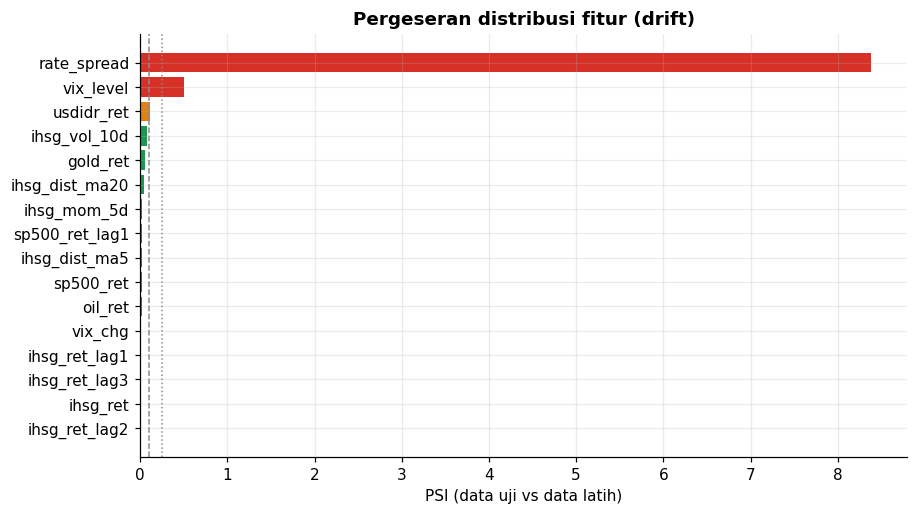

Fitur dengan pergeseran besar: ['rate_spread', 'vix_level']


,latih_min,latih_median,latih_max,uji_min,uji_median,uji_max
rate_spread,1.4000,4.8600,7.6400,0.4200,0.9200,1.5200
vix_level,9.7747,16.7400,42.2238,11.8600,16.6000,42.2238


In [5]:
def psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(expected, edges)[0] / len(expected), 1e-4, None)
    a = np.clip(np.histogram(actual, edges)[0] / len(actual), 1e-4, None)
    return float(np.sum((a - e) * np.log(a / e)))

FEATURES = meta['features']
drift = pd.DataFrame({'fitur': FEATURES, 'psi': [psi(train[c], test[c]) for c in FEATURES]}).sort_values('psi', ascending=False)
drift['kategori'] = pd.cut(drift.psi, [-np.inf, 0.10, 0.25, np.inf], labels=['Stabil', 'Moderat', 'Besar'])
display(drift.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 5))
dd = drift.iloc[::-1]
cmap = {'Stabil': C_UP, 'Moderat': C_ACCENT, 'Besar': C_DOWN}
ax.barh(dd.fitur, dd.psi, color=[cmap[c] for c in dd.kategori])
ax.axvline(0.10, color=C_GREY, ls='--', lw=1); ax.axvline(0.25, color=C_GREY, ls=':', lw=1)
ax.set_xlabel('PSI (data uji vs data latih)'); ax.set_title('Pergeseran distribusi fitur (drift)')
plt.savefig(FIG / '11_feature_drift_psi.png')
plt.show()
big_drift = drift[drift.kategori == 'Besar'].fitur.tolist()
print('Fitur dengan pergeseran besar:', big_drift or '-')
if big_drift:
    display(pd.DataFrame({c: {'latih_min': train[c].min(), 'latih_median': train[c].median(), 'latih_max': train[c].max(),
                              'uji_min': test[c].min(), 'uji_median': test[c].median(), 'uji_max': test[c].max()}
                          for c in big_drift}).T)

Variabel **level** (bukan perubahan) paling rentan bergeser: nilai periode uji bisa berada di luar rentang yang pernah
dilihat model. Model berbasis pohon tidak dapat mengekstrapolasi, sehingga fitur seperti itu praktis tidak berguna
(lihat juga *permutation importance* `rate_spread` ≈ 0 di Unit 10).

## 4. Keterbatasan (dihitung dari hasil, bukan asumsi)

In [6]:
yearly = pd.DataFrame(ev['yearly'])
econ = ev['economic']
hi = pd.DataFrame(ev['confidence_terciles']).set_index('keyakinan').loc['Tinggi']
limitations = [
    ('Sumber sinyal terkonsentrasi',
     f'Fitur terpenting adalah {top_feats[0]}; selisih AUC terhadap aturan sederhana "ikuti S&P 500" hanya {ev["vs_B3"]["roc_auc"]:+.3f}. '
     'Sebagian besar nilai prediktif berasal dari limpahan sesi AS semalam.'),
    ('Bukan strategi trading',
     'Target adalah arah penutupan-ke-penutupan. Informasi sesi AS sudah tercermin pada harga pembukaan BEI, '
     'sehingga keuntungan trading tidak dapat disimpulkan tanpa backtest harga pembukaan dan biaya transaksi.'),
    ('Kinerja bervariasi antarperiode',
     f'Akurasi per tahun pada periode uji berkisar {yearly.akurasi_model.min():.1%} – {yearly.akurasi_model.max():.1%}.'),
    ('Pergeseran rezim',
     f'PSI besar pada: {", ".join(big_drift) if big_drift else "tidak ada"}; variabel level (mis. selisih suku bunga) '
     'memiliki rentang berbeda pada periode uji.'),
    ('Kualitas & cakupan data',
     'Satu sumber data harian; penyimpangan kutipan < 4% mungkin tersisa; tidak ada data intrahari, volume, '
     'atau aliran dana asing.'),
    ('Kalibrasi probabilitas',
     f'Sepertiga prediksi paling yakin mencapai akurasi {hi.akurasi:.1%}; probabilitas belum dikalibrasi secara formal.'),
    ('Pemilihan hiperparameter kurang hemat',
     f'Tuning memilih {meta["tuned_params"]} untuk kenaikan F1 CV hanya '
     f'{meta["cv_tuned"]["f1_macro"] - meta["cv_default"]["f1_macro"]:+.4f}, padahal selisih F1 latih vs CV '
     f'{meta["overfit_gap_f1"]:.3f} (≥ 0,10) sudah menandakan overfitting.'),
]
display(pd.DataFrame(limitations, columns=['Keterbatasan', 'Penjelasan']))

,Keterbatasan,Penjelasan
0,Sumber sinyal terkonsentrasi,Fitur terpenting adalah sp500_ret; selisih AUC...
1,Bukan strategi trading,Target adalah arah penutupan-ke-penutupan. Inf...
2,Kinerja bervariasi antarperiode,Akurasi per tahun pada periode uji berkisar 53...
3,Pergeseran rezim,"PSI besar pada: rate_spread, vix_level; variab..."
4,Kualitas & cakupan data,Satu sumber data harian; penyimpangan kutipan ...
5,Kalibrasi probabilitas,Sepertiga prediksi paling yakin mencapai akura...
6,Pemilihan hiperparameter kurang hemat,"Tuning memilih {'max_depth': 8, 'min_samples_l..."


## 5. Rekomendasi perbaikan

| Prioritas | Rekomendasi | Alasan / dampak yang diharapkan |
|---|---|---|
| Tinggi | Aturan parsimoni saat *tuning* (*one-standard-error rule*): pilih konfigurasi paling sederhana yang skornya masih dalam 1 simpangan baku dari yang terbaik | Mengurangi *overfitting*; tuning saat ini memilih pohon lebih dalam untuk kenaikan yang tidak bermakna |
| Tinggi | Ganti `rate_spread` (level) dengan perubahan atau arah kebijakan suku bunga | Nilai periode uji berada di luar rentang data latih (PSI sangat besar) |
| Tinggi | Backtest ekonomi memakai harga **pembukaan** BEI dan biaya transaksi | Menguji apakah sinyal bernilai setelah informasi semalam tercermin di harga pembukaan |
| Tinggi | Tambah fitur pasar Asia yang buka sebelum BEI (Nikkei 225, Kospi, ASX 200) dan *futures* S&P 500 pagi hari | Informasi yang lebih segar daripada penutupan S&P 500 |
| Tinggi | *Walk-forward retraining* bulanan dengan jendela bergulir | Mengurangi dampak pergeseran rezim |
| Sedang | Kalibrasi probabilitas (*isotonic*/*Platt*) + ambang "zona keyakinan" yang ditetapkan di data validasi | Probabilitas dapat dibaca langsung sebagai tingkat keyakinan |
| Sedang | Data aliran dana asing harian (*net foreign buy/sell*) dan volume transaksi | Faktor domestik yang belum terwakili |
| Rendah | Uji model sekuensial (LSTM/Temporal CNN) sebagai pembanding | Hanya bila data dan fitur bertambah; risiko *overfitting* tinggi pada sinyal lemah |

**Catatan integritas evaluasi:** data uji Jan 2023 – Mei 2026 sudah dipakai untuk menilai model ini. Perbaikan di atas
**tidak boleh** dinilai ulang dengan data uji yang sama (hasilnya akan bias optimistis). Siklus berikutnya harus dievaluasi
dengan data baru setelah Mei 2026 atau melalui *paralel run* pada fase pilot.

## 6. Rencana penerapan dan monitoring

,Waktu,Fase,Aktivitas,Penanggung jawab
0,Bulan 1–2,Pilot internal,Pipeline otomatis 06.30 WIB: unduh data penutu...,"Tim data science, analis riset"
1,Bulan 2–3,Paralel run,Prediksi dicatat tanpa dipakai; bandingkan den...,"Analis riset, manajemen risiko"
2,Bulan 3–4,Integrasi,Dashboard probabilitas + faktor pendorong; dis...,"Tim data science, kepatuhan"
3,Bulan 4–6,Operasional terbatas,Dipakai sebagai alat bantu riset; retraining b...,Manajer investasi
4,Berkelanjutan,Monitoring,"Akurasi & AUC bergulir 60 hari, PSI fitur bula...",Tim data science


,Metrik monitoring,Pemicu peringatan,Tindakan
0,Akurasi bergulir 60 hari,< 0.55 selama 20 hari berturut-turut,Investigasi + retraining
1,ROC-AUC bergulir 60 hari,< 0.58,Investigasi + retraining
2,PSI fitur (bulanan),"> 0,25 pada fitur utama",Kaji ulang fitur/rezim
3,Kualitas data harian,"Kutipan menyimpang > 4% dari median 21 hari, n...","Tahan prediksi, perbaiki data"
4,Kinerja vs baseline B3,"Model kalah dari ""ikuti S&P 500"" selama 3 bulan",Evaluasi ulang nilai tambah model


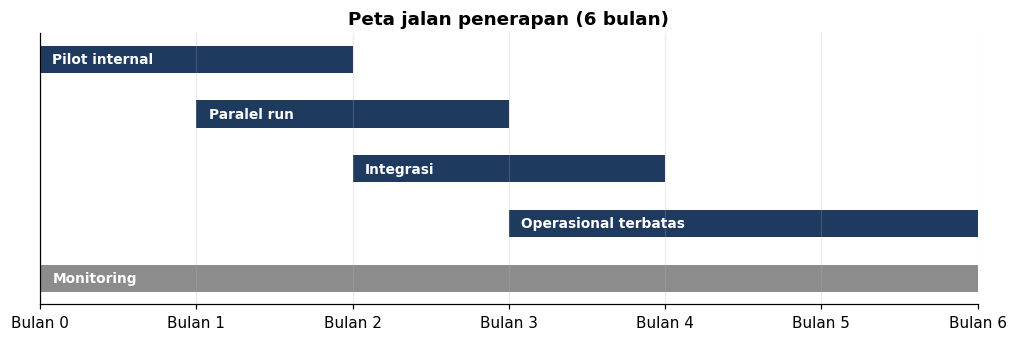

In [7]:
plan = pd.DataFrame([
    ('Bulan 1–2', 'Pilot internal', 'Pipeline otomatis 06.30 WIB: unduh data penutupan → validasi → fitur → prediksi → morning brief', 'Tim data science, analis riset'),
    ('Bulan 2–3', 'Paralel run', 'Prediksi dicatat tanpa dipakai; bandingkan dengan realisasi harian', 'Analis riset, manajemen risiko'),
    ('Bulan 3–4', 'Integrasi', 'Dashboard probabilitas + faktor pendorong; disclaimer disetujui kepatuhan', 'Tim data science, kepatuhan'),
    ('Bulan 4–6', 'Operasional terbatas', 'Dipakai sebagai alat bantu riset; retraining bulanan', 'Manajer investasi'),
    ('Berkelanjutan', 'Monitoring', 'Akurasi & AUC bergulir 60 hari, PSI fitur bulanan, cek kualitas data harian', 'Tim data science'),
], columns=['Waktu', 'Fase', 'Aktivitas', 'Penanggung jawab'])
display(plan)

monitor = pd.DataFrame([
    ('Akurasi bergulir 60 hari', f'< {tech["kpi"]["T1_accuracy_min"]:.2f} selama 20 hari berturut-turut', 'Investigasi + retraining'),
    ('ROC-AUC bergulir 60 hari', f'< {tech["kpi"]["T3_roc_auc_min"]:.2f}', 'Investigasi + retraining'),
    ('PSI fitur (bulanan)', '> 0,25 pada fitur utama', 'Kaji ulang fitur/rezim'),
    ('Kualitas data harian', 'Kutipan menyimpang > 4% dari median 21 hari, nilai kosong', 'Tahan prediksi, perbaiki data'),
    ('Kinerja vs baseline B3', 'Model kalah dari "ikuti S&P 500" selama 3 bulan', 'Evaluasi ulang nilai tambah model'),
], columns=['Metrik monitoring', 'Pemicu peringatan', 'Tindakan'])
display(monitor)

fig, ax = plt.subplots(figsize=(11, 3.2))
gantt = [('Pilot internal', 0, 2), ('Paralel run', 1, 3), ('Integrasi', 2, 4), ('Operasional terbatas', 3, 6), ('Monitoring', 0, 6)]
for i, (name, a, b) in enumerate(gantt):
    ax.barh(i, b - a, left=a, color=C_GREY if name == 'Monitoring' else C_NAVY, height=0.5)
    ax.text(a + 0.08, i, name, va='center', color='white', fontsize=9, fontweight='bold')
ax.set_yticks([]); ax.invert_yaxis(); ax.set_xlim(0, 6)
ax.set_xticks(range(7)); ax.set_xticklabels([f'Bulan {i}' for i in range(7)])
ax.set_title('Peta jalan penerapan (6 bulan)')
plt.savefig(FIG / '11_deployment_roadmap.png')
plt.show()

## 7. Keputusan review

In [8]:
all_pass = ev['all_kpi_passed']
if all_pass:
    decision = ('**LANJUT ke pilot terbatas** sebagai alat bantu riset (*decision support*), dengan syarat backtest harga '
                'pembukaan dan monitoring dijalankan. **Belum layak** sebagai sinyal trading otomatis.')
else:
    failed = kpi[~kpi.Lulus].Kode.tolist()
    decision = (f'**BELUM LANJUT ke pilot.** Kriteria {", ".join(failed)} belum terpenuhi; jalankan rekomendasi prioritas '
                'tinggi lalu ulangi siklus pemodelan.')
review_summary = {
    'model': meta['model_name'], 'metrics_test': m, 'all_kpi_passed': all_pass,
    'kpi': ev['kpi'], 'business_criteria': biz_eval.to_dict('records'),
    'top_features': top_feats, 'drift_high': big_drift,
    'limitations': [l[0] for l in limitations], 'decision': decision,
}
to_json(review_summary, REP / 'review_summary.json')
display(Markdown(f'''
### Keputusan
{decision}

Model **{meta["model_name"]}** mencapai accuracy {m["accuracy"]:.3f}, F1-macro {m["f1_macro"]:.3f}, dan ROC-AUC {m["roc_auc"]:.3f}
pada {ev["n_test"]:,} hari bursa yang tidak pernah dilihat ({ev["test_period"][0]} s.d. {ev["test_period"][1]}).
'''))


### Keputusan
**BELUM LANJUT ke pilot.** Kriteria T3 belum terpenuhi; jalankan rekomendasi prioritas tinggi lalu ulangi siklus pemodelan.

Model **Random Forest** mencapai accuracy 0.560, F1-macro 0.558, dan ROC-AUC 0.569
pada 787 hari bursa yang tidak pernah dilihat (2023-01-25 s.d. 2026-05-26).


## 8. Matriks keterlacakan (unit kompetensi → notebook → artefak)

In [9]:
ROOT = Path('..')
trace = [
    (1, 'Menentukan Objektif Bisnis', '01_business_objective.ipynb', ['reports/business_objective.json', 'figures/01_stakeholder_map.png']),
    (2, 'Menentukan Tujuan Teknis Data Science', '02_technical_objective.ipynb', ['reports/technical_objective.json', 'figures/02_information_timeline.png']),
    (3, 'Menelaah Data', '03_data_review.ipynb', ['reports/raw_data_dictionary.csv', 'figures/03_correlation_leadlag.png']),
    (4, 'Memvalidasi Data', '04_data_validation.ipynb', ['reports/validation_report.csv', 'reports/anomalies.csv', 'figures/04_usdidr_glitches.png']),
    (5, 'Menentukan Objek Data', '05_data_object.ipynb', ['reports/object_definition.json', 'reports/feature_plan.csv']),
    (6, 'Membersihkan Data', '06_data_cleaning.ipynb', ['reports/cleaning_log.csv', 'data/processed/market_clean.csv']),
    (7, 'Mengkonstruksi Data', '07_data_construction.ipynb', ['reports/split_info.json', 'data/processed/train.csv', 'models/clip_bounds.json']),
    (8, 'Membangun Skenario Model', '08_model_scenario.ipynb', ['reports/model_scenarios.json', 'figures/08_timeseries_cv.png']),
    (9, 'Membangun Model', '09_model_building.ipynb', ['reports/cv_results.csv', 'models/best_model.pkl', 'models/model_metadata.json']),
    (10, 'Mengevaluasi Hasil Pemodelan', '10_model_evaluation.ipynb', ['reports/evaluation_metrics.json', 'reports/test_predictions.csv']),
    (11, 'Melakukan Proses Review Pemodelan', '11_model_review.ipynb', ['reports/review_summary.json', 'figures/11_feature_drift_psi.png']),
]
rows = []
for no, unit, nb, arts in trace:
    ok = [(ROOT / a).exists() for a in arts]
    rows.append({'Unit': no, 'Unit kompetensi': unit, 'Notebook': nb, 'Artefak': ', '.join(arts),
                 'Artefak tersedia': f'{sum(ok)}/{len(ok)}'})
trace_df = pd.DataFrame(rows)
display(trace_df)
print('Seluruh artefak tersedia:', all(r['Artefak tersedia'].split('/')[0] == r['Artefak tersedia'].split('/')[1] for r in rows))

,Unit,Unit kompetensi,Notebook,Artefak,Artefak tersedia
0,1,Menentukan Objektif Bisnis,01_business_objective.ipynb,"reports/business_objective.json, figures/01_st...",2/2
1,2,Menentukan Tujuan Teknis Data Science,02_technical_objective.ipynb,"reports/technical_objective.json, figures/02_i...",2/2
2,3,Menelaah Data,03_data_review.ipynb,"reports/raw_data_dictionary.csv, figures/03_co...",2/2
3,4,Memvalidasi Data,04_data_validation.ipynb,"reports/validation_report.csv, reports/anomali...",3/3
4,5,Menentukan Objek Data,05_data_object.ipynb,"reports/object_definition.json, reports/featur...",2/2
5,6,Membersihkan Data,06_data_cleaning.ipynb,"reports/cleaning_log.csv, data/processed/marke...",2/2
6,7,Mengkonstruksi Data,07_data_construction.ipynb,"reports/split_info.json, data/processed/train....",3/3
7,8,Membangun Skenario Model,08_model_scenario.ipynb,"reports/model_scenarios.json, figures/08_times...",2/2
8,9,Membangun Model,09_model_building.ipynb,"reports/cv_results.csv, models/best_model.pkl,...",3/3
9,10,Mengevaluasi Hasil Pemodelan,10_model_evaluation.ipynb,"reports/evaluation_metrics.json, reports/test_...",2/2


Seluruh artefak tersedia: True


---
*Disclaimer: proyek ini adalah portofolio kompetensi data science. Hasilnya bukan rekomendasi investasi.*